## homework: resampling answers

**Station:** Ashalim, 2024, 10-minute data from the IMS (`ashalim_2024.csv`), in the Negev desert.

## Import data and basic processing

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# settings for all the graphs: resolution, and no lines on the top and right of the axes
plt.rcParams.update({'figure.dpi': 110,
                     'axes.spines.top': False,
                     'axes.spines.right': False})

def month_axis(ax):
    """show month names on the horizontal axis"""
    ax.xaxis.set_major_locator(mdates.MonthLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter('%b'))

In [2]:
filename = "ashalim_2024.csv"

# the IMS writes '-' where there is no measurement
df = pd.read_csv(filename, na_values=['-'])

# the IMS column that holds the time starts with "Date & Time"
time_column = [c for c in df.columns if c.startswith('Date & Time')][0]

# turn the text into datetimes (the day comes first!) and use them as the index
df['date'] = pd.to_datetime(df[time_column], dayfirst=True)
df = df.set_index('date')

# shorter names for the columns we will use
df = df.rename(columns={'Temperature (°C)': 'temperature',
                        'Rainfall (mm)': 'rain',
                        'Relative humidity (%)': 'humidity',
                        'Global radiation (W/m^2)': 'radiation'})

# the file ends with a single record from 2025-01-01 00:00, we keep only 2024
df = df.loc['2024']
df.head()

,Station,Date & Time (Winter),radiation,humidity,temperature,rain
date,,,,,,
2024-01-01 00:00:00,Ashalim,01/01/2024 00:00,0.0,95.0,8.8,0.0
2024-01-01 00:10:00,Ashalim,01/01/2024 00:10,0.0,95.0,8.4,0.0
2024-01-01 00:20:00,Ashalim,01/01/2024 00:20,0.0,95.0,8.3,0.0
2024-01-01 00:30:00,Ashalim,01/01/2024 00:30,0.0,95.0,7.9,0.0
2024-01-01 00:40:00,Ashalim,01/01/2024 00:40,0.0,94.0,7.6,0.0


Let's check the data.

In [3]:
# the time between consecutive records should always be 10 minutes: look for longer gaps
step = df.index.to_series().diff()
print("gaps longer than 30 minutes:")
print(step[step > pd.Timedelta('30min')])
print()

# how many records are missing, compared with a full year?
expected = 366 * 24 * 6   # 2024 is a leap year
print(f"records: {len(df)}, expected for a full year: {expected}, missing: {expected - len(df)}")
print()

# the records that exist, but are empty (NaN)
print(df[['radiation', 'humidity', 'temperature', 'rain']].isna().sum())

gaps longer than 30 minutes:
date
2024-01-29 12:30:00   1 days 13:40:00
2024-05-09 13:10:00   0 days 00:40:00
2024-05-29 14:40:00   0 days 02:00:00
2024-07-23 09:20:00   0 days 07:50:00
Name: date, dtype: timedelta64[ns]

records: 52409, expected for a full year: 52704, missing: 295

radiation      35
humidity       14
temperature    15
rain            2
dtype: int64


295 of the 52,704 records of the year are missing (0.6%). The longest gap is 1.5 days, on 28-29 January, and there are also 8 hours missing on 23 July. Careful: the sum of a day without records is 0, not NaN, so a day without data looks like a day without rain or sun.

## Part 1: the classics

### Graph 1: daily maximum humidity (bonus: daily minimum)

**My prediction:** at night the air cools and the humidity rises, while in the afternoon the desert air is dry. I expect a daily maximum of 70-95% and a minimum of 10-30%, with the maximum varying little compared with the minimum.

standard deviation of each line during the year (percentage points):
min     11.6
mean    12.8
max     11.3
dtype: float64

monthly means of each line:
date   Jan   Feb   Mar   Apr   May   Jun   Jul   Aug   Sep   Oct   Nov   Dec
min   37.0  36.0  28.0  29.0  27.0  24.0  26.0  28.0  35.0  34.0  40.0  34.0
mean  65.0  65.0  56.0  57.0  55.0  55.0  58.0  63.0  63.0  60.0  69.0  61.0
max   87.0  89.0  84.0  86.0  84.0  85.0  88.0  91.0  87.0  83.0  91.0  86.0


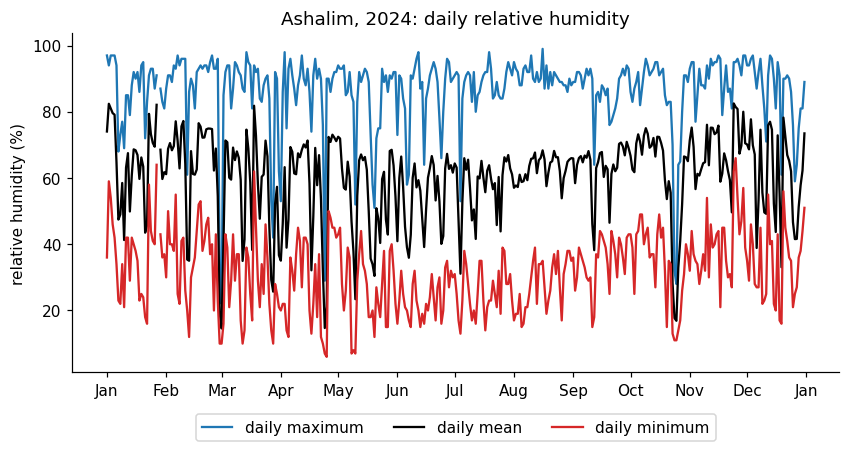

In [4]:
# one resample, three statistics: the daily minimum, mean and maximum
daily_hum = df['humidity'].resample('D').agg(['min', 'mean', 'max'])

# plotting
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(daily_hum['max'], color='tab:blue', label='daily maximum')
ax.plot(daily_hum['mean'], color='black', label='daily mean')
ax.plot(daily_hum['min'], color='tab:red', label='daily minimum')
month_axis(ax)
ax.set(ylabel='relative humidity (%)', title='Ashalim, 2024: daily relative humidity')
ax.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.1))

# how much does each line vary during the year?
print("standard deviation of each line during the year (percentage points):")
print(daily_hum.std().round(1))
print()

# the monthly mean of each line
print("monthly means of each line:")
monthly_hum = daily_hum.resample('ME').mean().round(0)
print(monthly_hum.set_index(monthly_hum.index.strftime('%b')).T)

**What I found, and why:** the maximum is high (85-95%) and the minimum is low (10-40%), as expected. But I was wrong about the variability: the maximum varies as much as the minimum (standard deviation of 11 points), and the daily mean varies the most (13 points). On dry days (1 March, 24 April, 24-25 October) the whole curve collapses, even the daily maximum falls to 22-32%.

### Graph 2: rainy days per month

**My prediction:** very few rainy days, all in winter, many of them just traces. With at least 5 mm I expect almost none.

smallest non-zero value in the rain column: 0.1 mm
total rain in the year: 17.1 mm

date           Jan  Feb  Mar  Apr  May  Jun  Jul  Aug  Sep  Oct  Nov  Dec
above 0 mm       2    5    3    0    1    0    0    0    0    0    3    3
at least 1 mm    2    1    0    0    0    0    0    0    0    0    3    1
at least 5 mm    0    0    0    0    0    0    0    0    0    0    0    0

total in the year:
above 0 mm       17
at least 1 mm     7
at least 5 mm     0
dtype: int64


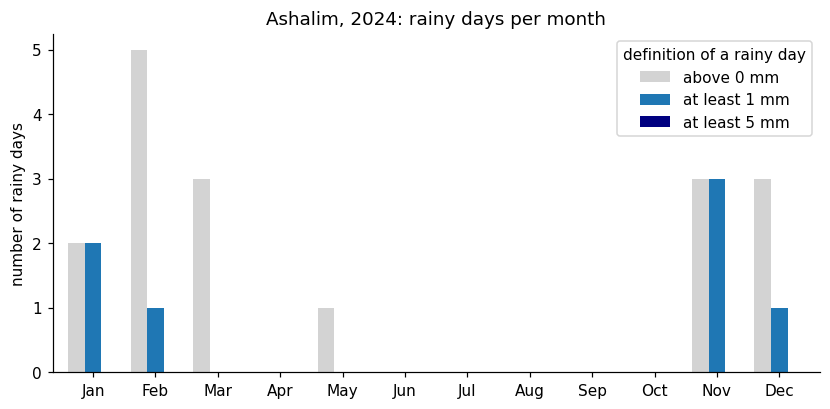

In [5]:
# the rain of each day is the sum of its 10-minute records
daily_rain = df['rain'].resample('D').sum()

# the smallest non-zero value is the resolution of the rain gauge
print("smallest non-zero value in the rain column:", df['rain'][df['rain'] > 0].min(), "mm")
print(f"total rain in the year: {daily_rain.sum():.1f} mm")

# number of rainy days in each month, with three definitions of "rainy day":
# a boolean series (True/False) summed by month counts the True values
counts = pd.DataFrame({'above 0 mm': (daily_rain > 0).resample('ME').sum(),
                       'at least 1 mm': (daily_rain >= 1).resample('ME').sum(),
                       'at least 5 mm': (daily_rain >= 5).resample('ME').sum()})
counts.index = counts.index.strftime('%b')   # month names instead of dates

# plotting
fig, ax = plt.subplots(figsize=(9, 4))
counts.plot.bar(ax=ax, color=['lightgray', 'tab:blue', 'navy'], width=0.8)
ax.set(xlabel='', ylabel='number of rainy days', title='Ashalim, 2024: rainy days per month')
ax.tick_params(axis='x', rotation=0)
ax.legend(title='definition of a rainy day')

# the numbers behind the graph
print()
print(counts.T)
print()
print("total in the year:")
print(counts.sum())

**What I found, and why:** there are 17 days with rain above 0 mm, 7 with at least 1 mm, and none with at least 5 mm. So the answer to "how many rainy days?" depends on the definition. The year was drier than I expected (17.1 mm in total), and the smallest non-zero value is 0.1 mm, the resolution of the gauge. The station was off on 28-29 January, right after the wettest day, so we don't know what happened then.

### Graph 3: hours of sun per day

**My prediction:** clear skies, so a smooth curve, about 14 hours in June and 10 hours in December, with dips on cloudy winter days. The 1 W/m$^2$ threshold should be the closest to the real day length, and 120 W/m$^2$ should lose 1-2 hours.

days without enough radiation records: 4
            1 W/m²  10 W/m²  50 W/m²  120 W/m²  astronomical
date                                                        
2024-06-21   14.17    13.83    13.00     12.17         14.16
2024-12-21   10.17     9.83     9.17      8.50         10.14


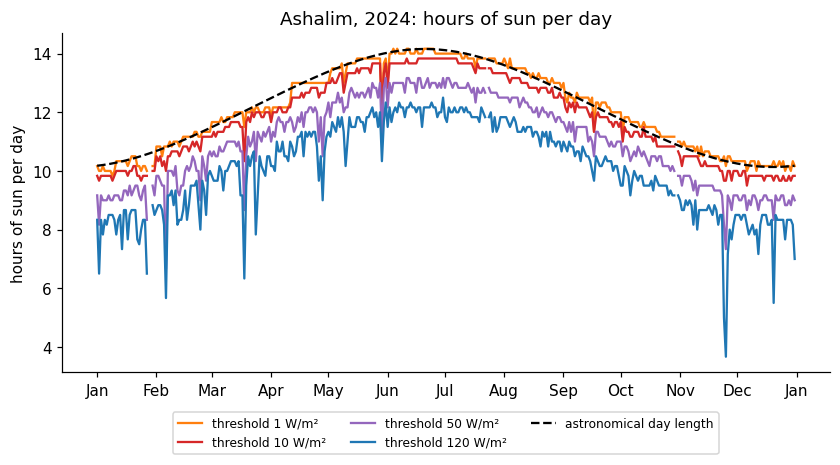

In [6]:
# a day without records would have a sum of 0, and look like a day without sun!
# so we keep only the days with at least 90% of the records (144 records per day)
valid_records = df['radiation'].resample('D').count()
complete_day = valid_records >= 0.9 * 144
print(f"days without enough radiation records: {(~complete_day).sum()}")

# hours of sun: count the records above the threshold, and divide by 6 (records per hour)
thresholds = [1, 10, 50, 120]
sun_hours = pd.DataFrame({f'{t} W/m²': ((df['radiation'] > t).resample('D').sum() / 6).where(complete_day)
                          for t in thresholds})

# the real day length, computed from the position of the sun, for comparison
latitude = 30.97   # approximate latitude of Ashalim
def day_length(date):
    n = date.dayofyear
    declination = np.deg2rad(23.44) * np.sin(2 * np.pi * (284 + n) / 365)
    lat = np.deg2rad(latitude)
    cos_h = (np.sin(np.deg2rad(-0.833)) - np.sin(lat) * np.sin(declination)) / (np.cos(lat) * np.cos(declination))
    return 24 / np.pi * np.arccos(cos_h)
real_day = pd.Series([day_length(d) for d in sun_hours.index], index=sun_hours.index)

# plotting
fig, ax = plt.subplots(figsize=(9, 4))
for col, color in zip(sun_hours.columns, ['tab:orange', 'tab:red', 'tab:purple', 'tab:blue']):
    ax.plot(sun_hours[col], color=color, label=f'threshold {col}')
ax.plot(real_day, color='black', ls='--', label='astronomical day length')
month_axis(ax)
ax.set(ylabel='hours of sun per day', title='Ashalim, 2024: hours of sun per day')
ax.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.1), fontsize=8)

# thresholds vs. the real day length on the longest and the shortest day
summary = sun_hours.loc[['2024-06-21', '2024-12-21']].copy()
summary['astronomical'] = real_day.loc[['2024-06-21', '2024-12-21']]
print(summary.round(2))

**What I found, and why:** the 1 W/m$^2$ line matches the real day length (computed from the latitude: 14.2 h in June, 10.1 h in December) within a few minutes. Higher thresholds cut the morning and the evening: on 21 June, 10 W/m$^2$ loses 20 minutes, 50 W/m$^2$ about 1 hour, and 120 W/m$^2$ 2 hours. The 120 line also drops sharply on cloudy days, which the low thresholds ignore. So there is no single correct threshold: low for the day length (the photoperiod of a plant), high for bright sunshine. I removed 4 days with too few records, otherwise 28 January would show 0 hours of sun.

## Part 2: one signal, many time scales

**My prediction:** the daily cycle is clear in the hourly data and disappears with daily means. Only the seasons survive in the monthly data. Since the daily cycle is large in the desert, I expect the standard deviation to drop noticeably from hourly to daily.

standard deviation (°C) of the series at each resolution:
1 hour     7.77
6 hours    7.45
1 day      6.17
1 week     6.03
1 month    5.98
dtype: float64


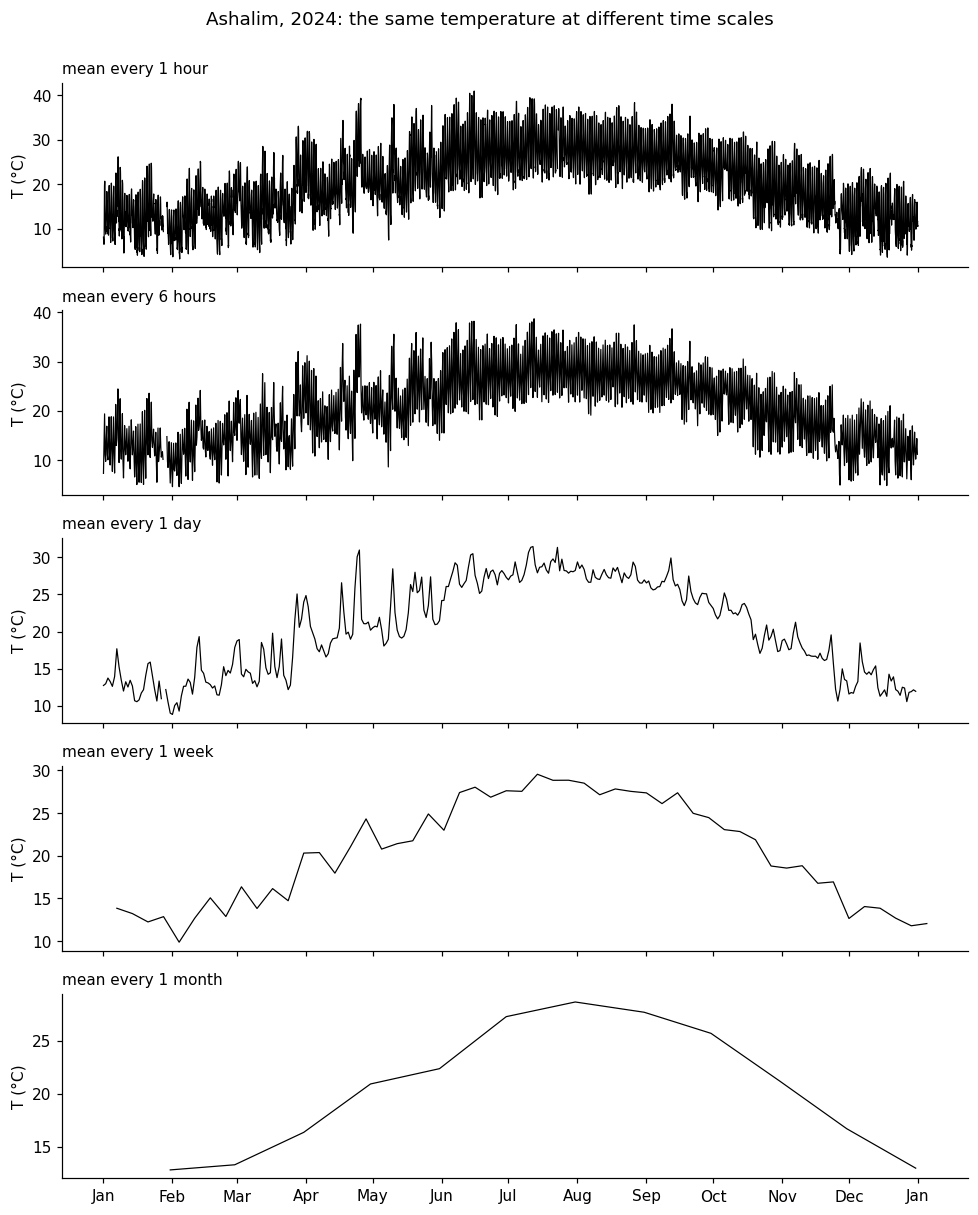

In [7]:
temp = df['temperature']

# the same variable at five resolutions: only the resampling rule changes
rules = ['1h', '6h', 'D', 'W', 'ME']
names = ['1 hour', '6 hours', '1 day', '1 week', '1 month']

# plotting: one panel for each resolution, all sharing the time axis
fig, axes = plt.subplots(len(rules), 1, sharex=True, figsize=(9, 11))
for ax, rule, name in zip(axes, rules, names):
    ax.plot(temp.resample(rule).mean(), color='black', lw=0.8)
    ax.set_ylabel('T (°C)')
    ax.set_title(f'mean every {name}', loc='left', fontsize=10)
month_axis(axes[-1])
fig.suptitle('Ashalim, 2024: the same temperature at different time scales', y=1.0)
fig.tight_layout()

# how much variability is left at each resolution?
print("standard deviation (°C) of the series at each resolution:")
print(pd.Series({name: temp.resample(rule).mean().std() for rule, name in zip(rules, names)}).round(2))

**What I found, and why:** the daily cycle is huge (about 14 °C on average), still visible with 6-hour means, and gone with daily means. The weekly means lose the day-to-day weather (the hot spell of 24-25 April is just a small bump), and the monthly means keep only the seasons. The standard deviation drops from 7.8 to 6.2 °C when the daily cycle disappears, as predicted, and then hardly changes. Note that each point is drawn at the end of its period, which is why the monthly curve starts in February.

The resolution must be finer than the process we study: the researcher of the leaf and the cloud needs minutes, while the one studying a drought can use weeks or months.

## Part 3: think like in the exam

**1. The monthly mean of the rain.**

In [8]:
# the mean of the records is the wrong way, the sum is the right way
wrong = df['rain'].resample('ME').mean()
right = df['rain'].resample('ME').sum()

# put both side by side, with the number of records behind each month
table = pd.DataFrame({'mean of the records (mm per 10 min)': wrong,
                      'sum of the records (mm per month)': right,
                      'records in the month': df['rain'].resample('ME').count()})
table.index = table.index.strftime('%b')
table.round(4)

,mean of the records (mm per 10 min),sum of the records (mm per month),records in the month
date,,,
Jan,0.0011,4.5,4239
Feb,0.0007,2.9,4174
Mar,0.0004,2.0,4464
Apr,0.0000,0.0,4318
May,0.0000,0.1,4449
Jun,0.0000,0.0,4320
Jul,0.0000,0.0,4418
Aug,0.0000,0.0,4464
Sep,0.0000,0.0,4313


They computed the average rain per 10-minute record, in mm per 10 minutes, and not the monthly total (in January, 0.0011 mm instead of 4.5 mm). Rain is an amount that accumulates, so we must **sum** it. Temperature is a state, so we **average** it. The function must match the physical meaning of the variable.

**2. Three ways to compute the yearly mean.**

In [9]:
# 1. the mean of all the records
mean_all = df['temperature'].mean()

# 2. the mean of the daily means
mean_daily = df['temperature'].resample('D').mean().mean()

# 3. the mean of the monthly means, first without and then with weights (the days in each month)
monthly_means = df['temperature'].resample('ME').mean()
mean_monthly = monthly_means.mean()
mean_monthly_weighted = np.average(monthly_means, weights=monthly_means.index.day)

print(f"mean of all records:          {mean_all:.3f} °C")
print(f"mean of the daily means:      {mean_daily:.3f} °C")
print(f"mean of the monthly means:    {mean_monthly:.3f} °C")
print(f"monthly means, weighted days: {mean_monthly_weighted:.3f} °C")

mean of all records:          20.527 °C
mean of the daily means:      20.525 °C
mean of the monthly means:    20.487 °C
monthly means, weighted days: 20.503 °C


They differ by less than 0.04 °C. The mean of the monthly means is the lowest, because it gives the 29 days of February the same weight as the 31 days of January, and overweights the cold months. Weighting by days helps, but January has 2 days without data. With complete data I prefer the mean of the daily means. The mean of the monthly means is for when we only have monthly values.

**3. The maximum of the daily means.**

In [10]:
# the maximum of the daily means: first the daily means, then the largest of them
daily_mean_t = df['temperature'].resample('D').mean()
print(f"maximum of the daily means: {daily_mean_t.max():.1f} °C on {daily_mean_t.idxmax().date()}")

# the maximum of all the records, and the daily mean of that same day
print(f"maximum temperature of the year: {df['temperature'].max():.1f} °C on {df['temperature'].idxmax()}")
print(f"daily mean on the day of the maximum: {daily_mean_t.loc[df['temperature'].idxmax().date().isoformat()]:.1f} °C")

maximum of the daily means: 31.4 °C on 2024-07-12
maximum temperature of the year: 41.1 °C on 2024-06-15 14:30:00
daily mean on the day of the maximum: 30.5 °C


No. The maximum of the daily means is 31.4 °C (12 July), and the maximum temperature of the year is 41.1 °C (15 June). On 15 June the temperature was above 37 °C from 11:00 to 16:00, but the cold night brought the daily mean down to 30.5 °C, an ordinary summer value. For the heat stress of a plant the extreme matters, and for the energy needed to cool a building the mean matters.

**4. Optional: the wind direction.**

In [11]:
# the ordinary mean does not work for angles
angles = np.array([350, 10])
print("ordinary mean:", angles.mean(), "°")

# average the vectors (the unit vectors pointing in each direction), then go back to an angle
rad = np.deg2rad(angles)
circular_mean = np.rad2deg(np.arctan2(np.sin(rad).mean(), np.cos(rad).mean())) % 360
print("circular mean:", round(circular_mean) % 360, "°")

ordinary mean: 180.0 °
circular mean: 0 °


350° and 10° are both nearly north, but the ordinary mean is 180°, which is south. Angles live on a circle, where 0° and 360° are the same. We should average the vectors (sines and cosines) and convert back to an angle, which gives 0°, north. (This dataset has no wind direction, so the code only illustrates the numbers of the question.)

## Bonus: my own graphs

### Bonus graph 1: the daily temperature range

The question: how large is the difference between the daily maximum and minimum temperature, and does it change during the year?

**My prediction:** a range of 12-18 °C, larger in the dry summer and smaller in winter.

date
Jan    12.7
Feb    12.0
Mar    14.4
Apr    14.4
May    14.9
Jun    17.3
Jul    14.9
Aug    14.6
Sep    13.4
Oct    14.6
Nov    13.4
Dec    13.7
dtype: float64

count    365.0
mean      14.2
std        3.4
min        3.8
25%       12.2
50%       14.3
75%       16.2
max       24.5
dtype: float64


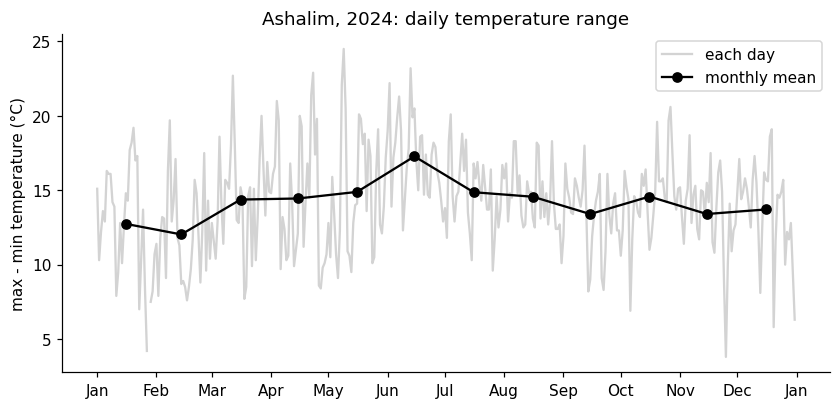

In [12]:
# the daily range is the daily maximum minus the daily minimum, then we take the monthly mean
daily_t = df['temperature'].resample('D').agg(['min', 'max'])
daily_range = daily_t['max'] - daily_t['min']
monthly_range = daily_range.resample('ME').mean()

# plotting: the monthly means are drawn in the middle of the month (the resample puts them at the end of it)
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(daily_range, color='lightgray', label='each day')
ax.plot(monthly_range.index - pd.Timedelta(days=15), monthly_range, color='black', marker='o', label='monthly mean')
month_axis(ax)
ax.set(ylabel='max - min temperature (°C)', title='Ashalim, 2024: daily temperature range')
ax.legend()

# the numbers behind the graph
print(monthly_range.round(1).set_axis(monthly_range.index.strftime('%b')))
print()
print(daily_range.describe().round(1))

**What I found, and why:** the mean range is 14.2 °C, as predicted, and it is smaller in winter (12-13 °C). But the largest month is June (17.3 °C), not the whole summer. I did not look for the reason, but June had the hottest day of the year (41.1 °C), so probably dry, hot spells.

### Bonus graph 2: the daily solar energy

The question: how much solar energy reaches the ground each day, in MJ/m$^2$, and how much do clouds subtract?

**My prediction:** about 28-30 MJ/m$^2$ in summer and 8-12 in winter, with cloudy days below half of that.

date
Jan    13.5
Feb    16.3
Mar    20.9
Apr    25.3
May    28.2
Jun    30.7
Jul    29.7
Aug    27.5
Sep    23.3
Oct    19.4
Nov    14.1
Dec    12.9
Name: radiation, dtype: float64

the 5 days with the least energy:
date
2024-11-25    4.4
2024-12-20    5.3
2024-02-06    6.7
2024-01-27    7.3
2024-11-24    7.4
Name: radiation, dtype: float64

yearly maximum: 31.6 MJ/m² on 2024-06-11


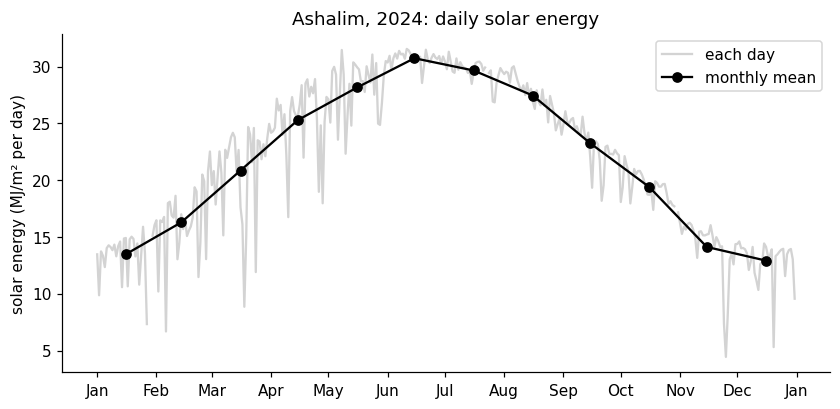

In [13]:
# the radiation is a power (W/m²): the mean power of the day times the seconds in a day gives the energy (J/m²)
# we use the mean, and not the sum, so that missing records do not reduce the result
# days with too few records (defined in Graph 3) are discarded
daily_energy = (df['radiation'].resample('D').mean() * 86400 / 1e6).where(complete_day)   # MJ/m² per day
monthly_energy = daily_energy.resample('ME').mean()

# plotting: the monthly means are drawn in the middle of the month
fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(daily_energy, color='lightgray', label='each day')
ax.plot(monthly_energy.index - pd.Timedelta(days=15), monthly_energy, color='black', marker='o', label='monthly mean')
month_axis(ax)
ax.set(ylabel='solar energy (MJ/m² per day)', title='Ashalim, 2024: daily solar energy')
ax.legend()

# the numbers behind the graph
print(monthly_energy.round(1).set_axis(monthly_energy.index.strftime('%b')))
print()
print("the 5 days with the least energy:")
print(daily_energy.nsmallest(5).round(1))
print(f"\nyearly maximum: {daily_energy.max():.1f} MJ/m² on {daily_energy.idxmax().date()}")

**What I found, and why:** the monthly mean goes from 30.7 MJ/m$^2$ in June to 12.9 in December, so the winter is higher than I predicted. The cloudiest day, 25 November, received 4.4 MJ/m$^2$, about a third of a typical November day. The radiation is a power (W/m$^2$), so I took the mean power times the 86,400 seconds of the day.

## AI declaration

This answer key was prepared with Claude Code (Claude), at the instructor's request: it wrote and ran the code and drafted the text. The instructor is responsible for the content.